<a href="https://colab.research.google.com/github/c5063565-coder/Voice/blob/main/voiceidentification_sample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip uninstall -y torchvision transformers diffusers gradio gradio-client

Found existing installation: torchvision 0.29.1+cu130
Uninstalling torchvision-0.29.1+cu130:
  Successfully uninstalled torchvision-0.29.1+cu130
Found existing installation: transformers 5.22.1
Uninstalling transformers-5.22.1:
  Successfully uninstalled transformers-5.22.1
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1
Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2


In [3]:
%pip install -q torch==2.8.0 torchaudio==2.8.0 speechbrain==1.0.3 huggingface_hub==0.36.0 soundfile scipy pandas scikit-learn matplotlib

In [5]:
import torch
import torchaudio
import speechbrain
import huggingface_hub

print("Torch:", torch.__version__)
print("Torchaudio:", torchaudio.__version__)
print("SpeechBrain:", speechbrain.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

from speechbrain.inference.classifiers import EncoderClassifier
print("Speaker-model import successful")

Torch: 2.8.0+cu128
Torchaudio: 2.8.0+cu128
SpeechBrain: 1.0.3
Hugging Face Hub: 0.36.0
Speaker-model import successful


In [7]:
from pathlib import Path
from zipfile import ZipFile
import random
import json
import shutil

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import matplotlib.pyplot as plt

from scipy.signal import resample_poly
from math import gcd
from IPython.display import Audio, display
from google.colab import files
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from speechbrain.inference.classifiers import EncoderClassifier

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [8]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [9]:
from pathlib import Path

DRIVE_FOLDER = Path("/content/drive/MyDrive/disserrtation")
ZIP_PATH = DRIVE_FOLDER / "dev-clean-1.zip"

if not ZIP_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {ZIP_PATH}\n"
        "Check the folder spelling in Google Drive."
    )

print("Dataset found:", ZIP_PATH)
print(f"Size: {ZIP_PATH.stat().st_size / (1024 ** 2):.2f} MB")

Dataset found: /content/drive/MyDrive/disserrtation/dev-clean-1.zip
Size: 15.51 MB


In [10]:
EXTRACT_DIR = Path("/content/voice_data")
EXTRACT_DIR.mkdir(exist_ok=True)

with ZipFile(ZIP_PATH) as archive:
    # Check paths before extracting.
    for item in archive.infolist():
        destination = (EXTRACT_DIR / item.filename).resolve()
        if not destination.is_relative_to(EXTRACT_DIR.resolve()):
            raise ValueError("Invalid archive path")

    archive.extractall(EXTRACT_DIR)

candidates = [
    path for path in EXTRACT_DIR.rglob("dev-clean-1")
    if (path / "174").is_dir() and (path / "251").is_dir()
]

if len(candidates) != 1:
    raise ValueError("Could not uniquely locate the two-speaker dataset")

DATA_ROOT = candidates[0]

for speaker in ["174", "251"]:
    for chapter in sorted((DATA_ROOT / speaker).iterdir()):
        if chapter.is_dir():
            count = len(list(chapter.glob("*.flac")))
            print(f"Speaker {speaker} | Chapter {chapter.name}: {count} recordings")

Speaker 174 | Chapter 168635: 23 recordings
Speaker 174 | Chapter 50561: 20 recordings
Speaker 174 | Chapter 84280: 16 recordings
Speaker 251 | Chapter 118436: 24 recordings
Speaker 251 | Chapter 136532: 24 recordings
Speaker 251 | Chapter 137823: 27 recordings


In [11]:
CHAPTERS = {
    "174": {
        "enrolment": "50561",
        "validation": "84280",
        "test": "168635",
    },
    "251": {
        "enrolment": "118436",
        "validation": "136532",
        "test": "137823",
    },
}

rng = random.Random(42)
rows = []

for speaker, splits in CHAPTERS.items():
    for split, chapter in splits.items():
        audio_files = sorted(
            (DATA_ROOT / speaker / chapter).glob("*.flac")
        )

        if len(audio_files) < 10:
            raise ValueError(
                f"Not enough files: speaker {speaker}, chapter {chapter}"
            )

        selected = rng.sample(audio_files, 10)

        for path in selected:
            info = sf.info(path)

            rows.append({
                "path": str(path),
                "speaker_id": speaker,
                "chapter_id": chapter,
                "split": split,
                "duration_seconds": info.duration,
            })

manifest = pd.DataFrame(rows)

assert manifest["path"].is_unique, "A recording appears in multiple splits"

display(pd.crosstab(manifest["speaker_id"], manifest["split"]))
print("Total selected recordings:", len(manifest))

split,enrolment,test,validation
speaker_id,,,
174,10,10,10
251,10,10,10


Total selected recordings: 60


In [12]:
for speaker in ["174", "251"]:
    row = manifest[
        (manifest["speaker_id"] == speaker)
        & (manifest["split"] == "enrolment")
    ].iloc[0]

    audio, sample_rate = sf.read(row["path"])

    print("Speaker:", speaker)
    display(Audio(audio, rate=sample_rate))

Speaker: 174


Speaker: 251


In [13]:
encoder = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    savedir="/content/pretrained_ecapa",
    run_opts={"device": DEVICE},
)

encoder.eval()
print("ECAPA-TDNN loaded")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


hyperparams.yaml: 0.00B [00:00, ?B/s]

DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/hyperparams.yaml' -> '/content/pretrained_ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch custom.py: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
/usr/local/lib/python3.13/dist-packages/speechbrain/utils/torch_audio_backend.py:57: UserWarning: torchaudio._backend.list_audio_backends has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be removed from the 2.9 release. 
  available_backends = torchaudio.list_audio_backends()
DEBUG:speechbrain.utils.checkpoints:Registered che

embedding_model.ckpt:   0%|          | 0.00/83.3M [00:00<?, ?B/s]

DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/embedding_model.ckpt' -> '/content/pretrained_ecapa/embedding_model.ckpt'
DEBUG:speechbrain.utils.parameter_transfer:Set local path in self.paths["embedding_model"] = /content/pretrained_ecapa/embedding_model.ckpt
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


mean_var_norm_emb.ckpt:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

... (2 outputs left out)

DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/classifier.ckpt' -> '/content/pretrained_ecapa/classifier.ckpt'
DEBUG:speechbrain.utils.parameter_transfer:Set local path in self.paths["classifier"] = /content/pretrained_ecapa/classifier.ckpt
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


label_encoder.txt: 0.00B [00:00, ?B/s]

DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/label_encoder.txt' -> '/content/pretrained_ecapa/label_encoder.ckpt'
DEBUG:speechbrain.utils.parameter_transfer:Set local path in self.paths["label_encoder"] = /content/pretrained_ecapa/label_encoder.ckpt
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
DEBUG:speechbrain.utils.parameter_transfer:Redirecting (loading from local path): embedding_model -> /content/pretrained_ecapa/embedding_model.ckpt
DEBUG:speechbrain.utils.parameter_transfer:Redirecting (loading from local path): mean_var_norm_emb -> /content/pretrained_ecapa/mean_var_norm_emb.ckpt
DEBUG:speechbrain.utils.parameter_transfer:Redirecting (loading from local path): classifier -> /content/pretrained_ecapa/classifier.ckpt
DEBUG:speechbrain.utils.

ECAPA-TDNN loaded


In [14]:
def extract_embedding(audio_path):
    waveform, sample_rate = sf.read(
        str(audio_path),
        dtype="float32",
        always_2d=True,
    )

    # Convert stereo recordings to mono if needed.
    waveform = waveform.mean(axis=1)

    if not np.isfinite(waveform).all() or len(waveform) == 0:
        raise ValueError(f"Invalid audio: {audio_path}")

    if sample_rate != 16000:
        divisor = gcd(sample_rate, 16000)
        waveform = resample_poly(
            waveform,
            16000 // divisor,
            sample_rate // divisor,
        ).astype(np.float32)

    if np.max(np.abs(waveform)) < 1e-6:
        raise ValueError(f"Recording is silent: {audio_path}")

    signal = torch.from_numpy(
        np.ascontiguousarray(waveform)
    ).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        embedding = encoder.encode_batch(signal)

    embedding = embedding.squeeze().cpu().numpy()
    return embedding / max(np.linalg.norm(embedding), 1e-12)


embeddings = {}

for index, row in manifest.iterrows():
    embeddings[row["path"]] = extract_embedding(row["path"])

    if (index + 1) % 10 == 0:
        print(f"Processed {index + 1}/{len(manifest)} recordings")

print("Embedding size:", next(iter(embeddings.values())).shape)

Processed 10/60 recordings
Processed 20/60 recordings
Processed 30/60 recordings
Processed 40/60 recordings
Processed 50/60 recordings
Processed 60/60 recordings
Embedding size: (192,)


In [15]:
speaker_ids = sorted(manifest["speaker_id"].unique())
profiles = {}

for speaker in speaker_ids:
    paths = manifest.loc[
        (manifest["speaker_id"] == speaker)
        & (manifest["split"] == "enrolment"),
        "path",
    ]

    mean_embedding = np.mean(
        [embeddings[path] for path in paths],
        axis=0,
    )

    profiles[speaker] = (
        mean_embedding / max(np.linalg.norm(mean_embedding), 1e-12)
    )

profile_matrix = np.stack(
    [profiles[speaker] for speaker in speaker_ids]
)

print("Created profiles for:", speaker_ids)

Created profiles for: ['174', '251']


In [16]:
validation = manifest[
    manifest["split"] == "validation"
].copy()

genuine_scores = []
impostor_scores = []
validation_predictions = []

for _, row in validation.iterrows():
    scores = profile_matrix @ embeddings[row["path"]]
    true_index = speaker_ids.index(row["speaker_id"])

    genuine_scores.append(scores[true_index])
    impostor_scores.extend(np.delete(scores, true_index).tolist())

    validation_predictions.append(
        speaker_ids[int(np.argmax(scores))]
    )

genuine_scores = np.array(genuine_scores)
impostor_scores = np.array(impostor_scores)

thresholds = np.linspace(-1.0, 1.0, 2001)

balanced_errors = [
    0.5 * (
        np.mean(genuine_scores < threshold)
        + np.mean(impostor_scores >= threshold)
    )
    for threshold in thresholds
]

THRESHOLD = float(thresholds[np.argmin(balanced_errors)])

print(
    "Validation identification accuracy:",
    f"{accuracy_score(validation['speaker_id'], validation_predictions):.1%}",
)
print("Provisional similarity threshold:", round(THRESHOLD, 4))
print("Similarity scores are not probabilities.")

Validation identification accuracy: 100.0%
Provisional similarity threshold: 0.175
Similarity scores are not probabilities.


,file,actual,nearest_speaker,similarity,decision
0,174-168635-0006.flac,174,174,0.848985,174
1,174-168635-0020.flac,174,174,0.773808,174
2,174-168635-0017.flac,174,174,0.856077,174
3,174-168635-0013.flac,174,174,0.727913,174
4,174-168635-0007.flac,174,174,0.857650,174
5,174-168635-0014.flac,174,174,0.801366,174
6,174-168635-0008.flac,174,174,0.903687,174
7,174-168635-0000.flac,174,174,0.713228,174
8,174-168635-0012.flac,174,174,0.839705,174
9,174-168635-0021.flac,174,174,0.770095,174



Nearest-speaker accuracy: 100.0%
Correct identification after threshold: 100.0%
Uncertain rate: 0.0%

Classification report — nearest speaker:
              precision    recall  f1-score   support

         174       1.00      1.00      1.00        10
         251       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



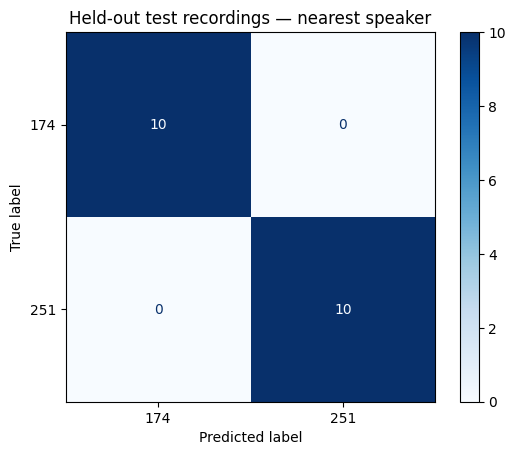

In [17]:
test = manifest[manifest["split"] == "test"].copy()
results = []

for _, row in test.iterrows():
    scores = profile_matrix @ embeddings[row["path"]]
    best_index = int(np.argmax(scores))
    best_score = float(scores[best_index])
    nearest_speaker = speaker_ids[best_index]

    decision = (
        nearest_speaker
        if best_score >= THRESHOLD
        else "uncertain"
    )

    results.append({
        "file": Path(row["path"]).name,
        "actual": row["speaker_id"],
        "nearest_speaker": nearest_speaker,
        "similarity": best_score,
        "decision": decision,
    })

results_df = pd.DataFrame(results)
display(results_df)

print(
    "\nNearest-speaker accuracy:",
    f"{accuracy_score(results_df['actual'], results_df['nearest_speaker']):.1%}",
)

print(
    "Correct identification after threshold:",
    f"{np.mean(results_df['actual'] == results_df['decision']):.1%}",
)

print(
    "Uncertain rate:",
    f"{np.mean(results_df['decision'] == 'uncertain'):.1%}",
)

print("\nClassification report — nearest speaker:")
print(classification_report(
    results_df["actual"],
    results_df["nearest_speaker"],
    labels=speaker_ids,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    results_df["actual"],
    results_df["nearest_speaker"],
    labels=speaker_ids,
    cmap="Blues",
)

plt.title("Held-out test recordings — nearest speaker")
plt.show()

In [18]:
new_upload = files.upload()

for filename in new_upload:
    if Path(filename).suffix.lower() not in {".wav", ".flac"}:
        print(f"Skipped {filename}: please use WAV or FLAC")
        continue

    embedding = extract_embedding(filename)
    scores = profile_matrix @ embedding

    best_index = int(np.argmax(scores))
    best_score = float(scores[best_index])

    decision = (
        speaker_ids[best_index]
        if best_score >= THRESHOLD
        else "Unknown/uncertain"
    )

    print("\nFile:", filename)
    print("Decision:", decision)

    for speaker, score in zip(speaker_ids, scores):
        print(f"Similarity to speaker {speaker}: {score:.4f}")

del new_upload

Saving 174-168635-0022.flac to 174-168635-0022.flac

File: 174-168635-0022.flac
Decision: 174
Similarity to speaker 174: 0.7849
Similarity to speaker 251: 0.0414


In [19]:
OUTPUT_DIR = Path("/content/voice_identification_results")
OUTPUT_DIR.mkdir(exist_ok=True)

np.savez(
    OUTPUT_DIR / "speaker_profiles.npz",
    speaker_ids=np.array(speaker_ids),
    profiles=profile_matrix,
)

manifest_to_save = manifest.copy()
manifest_to_save["path"] = manifest_to_save["path"].map(
    lambda path: str(Path(path).relative_to(DATA_ROOT))
)

manifest_to_save.to_csv(
    OUTPUT_DIR / "selected_recordings.csv",
    index=False,
)

results_df.to_csv(
    OUTPUT_DIR / "test_results.csv",
    index=False,
)

with open(OUTPUT_DIR / "settings.json", "w") as file:
    json.dump({
        "model": "speechbrain/spkrec-ecapa-voxceleb",
        "sample_rate": 16000,
        "threshold": THRESHOLD,
        "threshold_status": "provisional_two_speaker_validation",
        "method": "normalised_mean_enrolment_embeddings_cosine_similarity",
        "torch_version": torch.__version__,
    }, file, indent=2)

archive_path = shutil.make_archive(
    "/content/voice_identification_results",
    "zip",
    OUTPUT_DIR,
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>